# Estudo 03 – H2: o gap de abertura prevê o começo do pregão?

Hipótese H2 das [notas](../NOTAS.md). O **gap de abertura** é a diferença entre o preço de abertura de hoje e o fechamento de ontem:

$$\text{gap} = 100 \cdot \ln\frac{\text{abertura}_{\,hoje}}{\text{fechamento}_{\,ontem}} \quad (\%)$$

Ele resume tudo o que aconteceu durante a noite (notícias, mercados no exterior). Até aqui o protocolo **descartava** o gap. Duas ideias opostas circulam entre operadores:

- **"O gap fecha":** o preço tende a voltar ao fechamento de ontem (reversão), então se aposta **contra** o gap;
- **"O gap continua":** o movimento da noite segue na abertura (momentum), então se aposta **a favor**.

Perguntas:

1. Quantas observações temos, e o que dá para detectar com elas? (**poder estatístico**, conceito novo)
2. O gap prevê o retorno dos primeiros minutos, da primeira hora, do dia?
3. "O gap fecha 90% das vezes" é verdade? Isso é informação?
4. Há algo em gaps grandes?

**Dados:** WIN, só até 31/12/2024. Ficam de fora os **dias de rolagem** (o gap é o prêmio do contrato novo, não movimento; [notas](../NOTAS.md), Seção 2.2) e os pregões logo depois de um buraco na base.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

rng = np.random.default_rng(3)
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
CUSTOS = {nome: p["custo_pts"] for nome, p in cu.CENARIOS.items()}

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]
dia = win.index.normalize()
win["min_desde_abertura"] = (win.index - win.groupby(dia).apply(lambda x: x.index[0]).reindex(dia).values) / pd.Timedelta(minutes=1)

def vencimentos(anos):
    "WIN vence na quarta-feira mais próxima do dia 15 dos meses pares."
    out = []
    for y in anos:
        for m in [2, 4, 6, 8, 10, 12]:
            d15 = pd.Timestamp(y, m, 15); off = 2 - d15.weekday()
            off = off - 7 if off > 3 else off + 7 if off < -3 else off
            out.append(d15 + pd.Timedelta(days=off))
    return out

g = win.groupby(dia)
D = pd.DataFrame({"abertura": g.open.first(), "fechamento": g.close.last()})
D["fech_ontem"] = D.fechamento.shift()
D["dias_corridos"] = D.index.to_series().diff().dt.days
D["gap"] = np.log(D.abertura / D.fech_ontem) * 100
D["rolagem"] = D.index.isin(vencimentos(range(2020, 2026)))
D["pos_buraco"] = D.dias_corridos > 4

# preço de fechamento h minutos depois da abertura (h = 1 → fechamento do 1º minuto)
for h in [1, 5, 15, 30, 60, 120]:
    D[f"p{h}"] = win[win.min_desde_abertura <= h - 1].groupby(dia[win.min_desde_abertura <= h - 1]).close.last()
D["p_fim"] = D.fechamento
# excursões máximas a partir da abertura (para a análise de "fechar o gap")
for nome, T in [("60", 60), ("dia", 1e9)]:
    sub = win[win.min_desde_abertura < T]; gs = sub.groupby(sub.index.normalize())
    D[f"max_{nome}"] = np.log(gs.high.max() / D.abertura) * 100
    D[f"min_{nome}"] = np.log(gs.low.min() / D.abertura) * 100

G = D[~D.rolagem & ~D.pos_buraco & D.gap.notna()].copy()
print(f"pregões: {len(D)} · rolagem: {D.rolagem.sum()} · logo após buraco: {D.pos_buraco.sum()} · válidos: {len(G)}")

pregões: 934 · rolagem: 22 · logo após buraco: 10 · válidos: 903


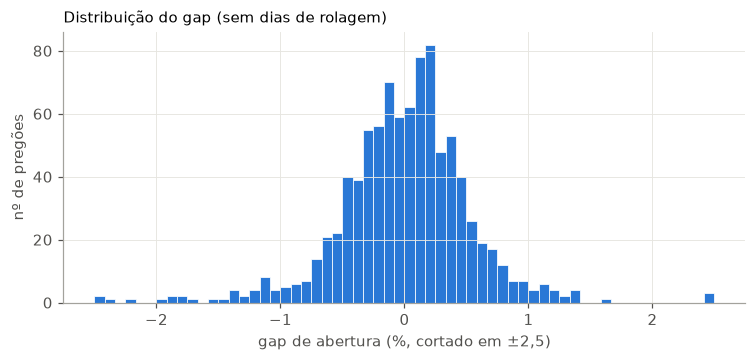

desvio do gap: 0.56% · |gap| mediano: 330 pts · |gap| > 0,5%: 24% dos dias · > 1%: 6%


In [2]:
pts_gap = (G.gap.abs() / 100 * G.fech_ontem)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(G.gap.clip(-2.5, 2.5), bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ax.set_xlabel("gap de abertura (%, cortado em ±2,5)"); ax.set_ylabel("nº de pregões")
ax.set_title("Distribuição do gap (sem dias de rolagem)", loc="left", fontsize=10); plt.show()
print(f"desvio do gap: {G.gap.std():.2f}% · |gap| mediano: {pts_gap.median():.0f} pts · "
      f"|gap| > 0,5%: {np.mean(G.gap.abs() > 0.5):.0%} dos dias · > 1%: {np.mean(G.gap.abs() > 1):.0%}")

O gap típico é de ~330 pontos, comparável a uma hora inteira de pregão. A noite carrega muito movimento, e por isso é tentador achar que ela "diz algo" sobre a manhã.

## 1. Poder estatístico: quanto dá para enxergar com uma operação por dia?

Até agora tínhamos centenas de milhares de observações (candles de 1 min). Aqui é **uma por dia**: ~900. Isso muda tudo.

**A conta básica:** se cada operação tem resultado com desvio-padrão σ (em pontos), a esperança medida em n operações tem erro-padrão **σ/√n**. Com uma operação de 60 min depois da abertura, σ ≈ 490 pts (a abertura é muito volátil) e n ≈ 900, o erro-padrão é ≈ 16 pts. Já é **o dobro do custo base** (7,5).

**Poder estatístico** é a probabilidade de um teste **detectar** um efeito que existe de verdade. Com o critério usual (|t| > 2), para ter 80% de chance de detectar um efeito, ele precisa ser ≈ **2,8 erros-padrão** de tamanho. É o **efeito mínimo detectável**. Abaixo dele, o efeito pode existir e mesmo assim passar despercebido na maioria das vezes.

Simulação: estratégias com vantagem verdadeira de e pts por operação, σ = 490, n = 900. Com que frequência o teste detecta?

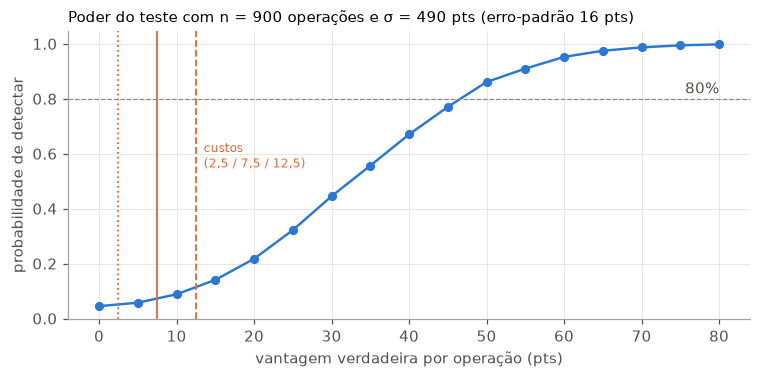

efeito mínimo detectável (80% de poder): ≈ 46 pts por operação


In [3]:
SIGMA, N, R = 490, 900, 4000
ep = SIGMA / np.sqrt(N)
efeitos = np.arange(0, 81, 5)
poder = [np.mean(np.abs((e + ep * rng.standard_normal(R)) / ep) > 2) for e in efeitos]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(efeitos, poder, "o-", color=AZUL, ms=5)
ax.axhline(0.8, color=CINZA, lw=0.8, ls="--"); ax.text(80, 0.82, "80%", ha="right", color="#52514e")
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.axvline(CUSTOS[nome], color=LARANJA, lw=1.2, ls=estilo)
ax.text(CUSTOS["conservador"] + 1, 0.55, "custos\n(2,5 / 7,5 / 12,5)", color=LARANJA, fontsize=8)
ax.set_xlabel("vantagem verdadeira por operação (pts)"); ax.set_ylabel("probabilidade de detectar")
ax.set_title(f"Poder do teste com n = {N} operações e σ = {SIGMA} pts (erro-padrão {ep:.0f} pts)", loc="left", fontsize=10)
plt.show()
print(f"efeito mínimo detectável (80% de poder): ≈ {2.8 * ep:.0f} pts por operação")

**Leitura:** com uma operação por dia, só enxergaríamos vantagens de **~45 pts por operação** ou mais. Uma estratégia que ganhasse 15 pts líquidos por operação (ótima: ~R$ 2.700 por ano por contrato) seria detectada só ~15% das vezes. **Ausência de evidência não é evidência de ausência**: aqui, "não significativo" quer dizer "não dá para saber", não "não existe".

Comparação com outras frequências (σ medido em cada caso, ~4 anos de dados):

| Estratégia | n | σ por operação | Erro-padrão | Efeito mínimo detectável |
|---|---|---|---|---|
| 1 operação por dia (60 min) | ~900 | ~490 pts | ~16 pts | **~45 pts** |
| A cada candle de 60 min | ~8.000 | ~405 pts | ~4,5 pts | ~13 pts |
| A cada candle de 5 min | ~100.000 | ~120 pts | ~0,37 pt | ~1 pt |

É a troca de sempre: candles pequenos dão **poder** mas o custo come o ganho (Estudo 01); estratégias raras evitam o custo mas **não dá para saber se funcionam**.

## 2. O gap prevê o retorno seguinte?

Para cada horizonte (5 min a fim do dia), medimos:

- a correlação entre o gap e o retorno a partir da entrada, com z robusto;
- o resultado de **apostar contra o gap** (estratégia "o gap fecha"), em pontos por operação, que é o custo de equilíbrio.

Duas entradas:

- **na abertura:** preço do leilão de abertura. É viável participar do leilão, e o preço teórico aparece durante a pré-abertura;
- **no fechamento do 1º minuto:** mais conservador.

In [4]:
def corr_z(x, y):
    x, y = x - x.mean(), y - y.mean()
    return (x * y).sum() / np.sqrt((x * x).sum() * (y * y).sum()), (x * y).sum() / np.sqrt((x * x * y * y).sum())

linhas = []
for entrada, col_e in [("abertura", "abertura"), ("fech. 1º min", "p1")]:
    for h in [5, 15, 30, 60, 120, "fim"]:
        col = f"p{h}" if h != "fim" else "p_fim"
        rho, z = corr_z(G.gap.values, np.log(G[col] / G[col_e]).values)
        contra = -np.sign(G.gap) * (G[col] - G[col_e])
        linhas.append(dict(entrada=entrada, ate_min=h, rho=rho, z_robusto=z,
                           contra_gap_pts=contra.mean(), erro_padrao=contra.std() / np.sqrt(len(contra))))
tab2 = pd.DataFrame(linhas)
tab2.round(3)

,entrada,ate_min,rho,z_robusto,contra_gap_pts,erro_padrao
0,abertura,5,0.056,1.223,2.569,8.665
1,abertura,15,0.042,0.995,2.121,10.834
2,abertura,30,0.051,1.404,2.060,12.887
3,abertura,60,-0.010,-0.241,9.385,16.219
4,abertura,120,-0.008,-0.133,14.236,25.362
5,abertura,fim,-0.018,-0.425,17.536,43.925
6,fech. 1º min,5,0.044,0.754,2.940,8.005
7,fech. 1º min,15,0.031,0.668,2.492,10.269
8,fech. 1º min,30,0.042,1.051,2.431,12.298
9,fech. 1º min,60,-0.019,-0.463,9.756,15.796


**Leitura:**

- Nenhuma correlação passa de |z| = 2. O sinal é levemente positivo nos primeiros 30 min (continuação) e levemente negativo depois (reversão), sempre dentro do ruído.
- Apostar contra o gap dá de +2 a +18 pts, mas com erro-padrão de 8 a 44 pts. **Compatível com zero e também com um lucro razoável.** É a falta de poder da Seção 1 em ação: não dá para saber.

## 3. "O gap fecha 90% das vezes": o teste do placebo

É comum ouvir que os gaps "quase sempre fecham", ou seja, que o preço volta a tocar o fechamento de ontem durante o dia. Vamos medir. Mas a pergunta certa é: **comparado com o quê?** O preço anda muito num pregão; um gap pequeno seria "fechado" mesmo que o caminho do preço não tivesse nada a ver com o gap.

**Placebo:** pegamos o gap de cada dia e o caminho do preço de **outro dia** sorteado. Num par assim, o caminho não sabe nada do gap. Se a taxa real for igual à do placebo, "fechar o gap" não traz informação nenhuma.

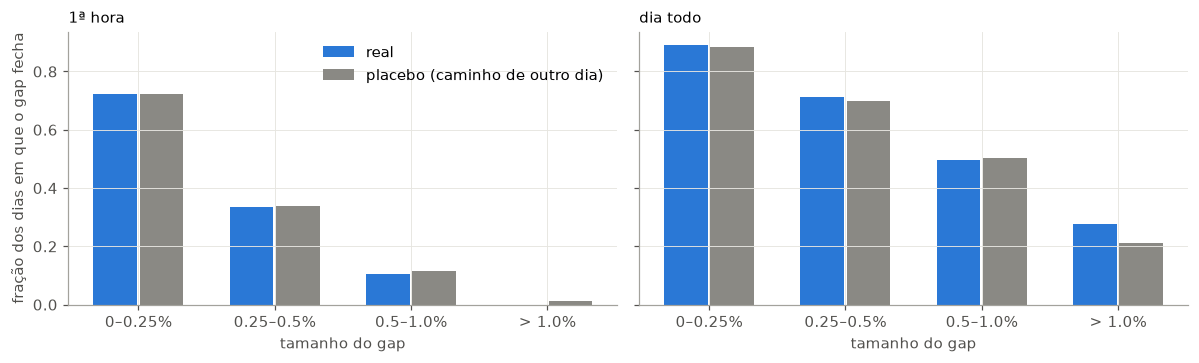

,janela,faixa_gap,n,fecha_real,fecha_placebo
0,1ª hora,0–0.25%,397,0.72,0.72
1,1ª hora,0.25–0.5%,275,0.33,0.34
2,1ª hora,0.5–1.0%,163,0.10,0.12
3,1ª hora,> 1.0%,58,0.00,0.01
4,dia todo,0–0.25%,397,0.89,0.88
5,dia todo,0.25–0.5%,275,0.71,0.70
6,dia todo,0.5–1.0%,163,0.50,0.50
7,dia todo,> 1.0%,58,0.28,0.21


In [5]:
def fecha(gap, mx, mn):
    "Gap de alta fecha se o preço cai até o fechamento de ontem; gap de baixa, se sobe."
    return np.where(gap > 0, mn <= -gap, mx >= -gap)

faixas = [(0, 0.25), (0.25, 0.5), (0.5, 1.0), (1.0, 99)]
linhas = []
for janela in ["60", "dia"]:
    gap, mx, mn = G.gap.values, G[f"max_{janela}"].values, G[f"min_{janela}"].values
    real = fecha(gap, mx, mn)
    plac = np.array([fecha(gap, mx[j], mn[j]) for j in (rng.permutation(len(gap)) for _ in range(500))])
    for a, b in faixas:
        m = (np.abs(gap) > a) & (np.abs(gap) <= b)
        linhas.append(dict(janela="1ª hora" if janela == "60" else "dia todo", faixa_gap=f"{a}–{b}%" if b < 99 else f"> {a}%",
                           n=m.sum(), fecha_real=real[m].mean(), fecha_placebo=plac[:, m].mean()))
tab3 = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, janela in zip(axs, ["1ª hora", "dia todo"]):
    d = tab3[tab3.janela == janela]; xs = np.arange(len(d))
    ax.bar(xs - 0.17, d.fecha_real, width=0.32, color=AZUL, label="real")
    ax.bar(xs + 0.17, d.fecha_placebo, width=0.32, color=CINZA, label="placebo (caminho de outro dia)")
    ax.set_xticks(xs, d.faixa_gap); ax.set_xlabel("tamanho do gap"); ax.set_title(janela, loc="left", fontsize=10)
axs[0].set_ylabel("fração dos dias em que o gap fecha"); axs[0].legend(frameon=False)
fig.tight_layout(); plt.show()
tab3.round(2)

**Leitura:** o "gap fecha" é real como **frequência**: 89% dos gaps pequenos fecham no dia. Mas o placebo dá **o mesmo** (88%). Os gaps fecham porque o preço anda o bastante num dia para cruzar uma distância pequena, não porque exista uma força puxando de volta. Uma estatística muito repetida e que **não contém informação**.

Lição geral: uma frequência impressionante só significa algo **comparada com uma referência** que tenha tudo igual, menos o efeito que se quer testar. O aleatório "nos mesmos candles" da reavaliação da frente ([notas](../NOTAS.md), Seção 4.2) é o mesmo princípio.

## 4. Gaps grandes: um candidato (com cuidado)

Olhando só os gaps maiores que 0,5% (~1 em cada 4 dias), o resultado de apostar **contra** o gap nos primeiros minutos é negativo, ou seja, **a favor** do gap ganha: o movimento da noite **continua** na abertura.

In [6]:
linhas = []
for lim in [0, 0.5, 1.0]:
    s = G[G.gap.abs() > lim]
    for h in [5, 15, 60, "fim"]:
        col = f"p{h}" if h != "fim" else "p_fim"
        for entrada, col_e in [("abertura", "abertura"), ("fech. 1º min", "p1")]:
            a_favor = np.sign(s.gap) * (s[col] - s[col_e])
            linhas.append(dict(gap_minimo=lim, ate_min=h, entrada=entrada, n=len(s), a_favor_pts=a_favor.mean(),
                               erro_padrao=a_favor.std() / np.sqrt(len(s)), t=a_favor.mean() / (a_favor.std() / np.sqrt(len(s)))))
tab4 = pd.DataFrame(linhas)
tab4.round(2)

,gap_minimo,ate_min,entrada,n,a_favor_pts,erro_padrao,t
0,0.0,5,abertura,893,-2.60,8.76,-0.30
1,0.0,5,fech. 1º min,893,-2.97,8.09,-0.37
2,0.0,15,abertura,893,-2.14,10.96,-0.20
3,0.0,15,fech. 1º min,893,-2.52,10.38,-0.24
4,0.0,60,abertura,893,-9.49,16.40,-0.58
5,0.0,60,fech. 1º min,893,-9.87,15.97,-0.62
6,0.0,fim,abertura,893,-17.73,44.42,-0.40
7,0.0,fim,fech. 1º min,893,-18.11,44.28,-0.41
8,0.5,5,abertura,221,52.08,19.75,2.64
9,0.5,5,fech. 1º min,221,44.00,19.21,2.29


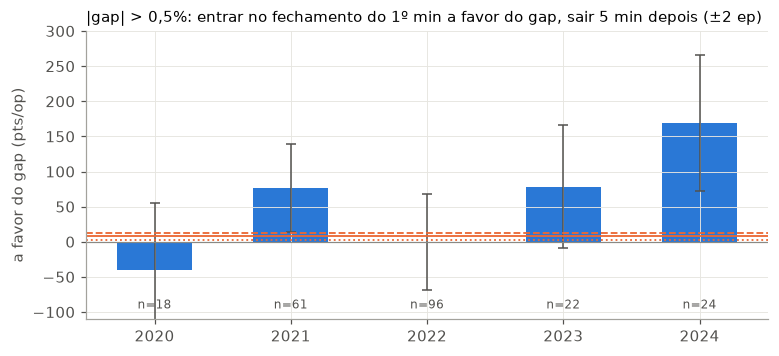

total: +44.0 ± 19.2 pts por operação, n = 221


In [7]:
s = G[G.gap.abs() > 0.5]
a_favor = np.sign(s.gap) * (s.p5 - s.p1)
por_ano = a_favor.groupby(s.index.year).agg(n="size", media="mean", ep=lambda x: x.std() / np.sqrt(len(x)))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(por_ano.index.astype(str), por_ano.media, color=AZUL, width=0.55)
ax.errorbar(por_ano.index.astype(str), por_ano.media, yerr=2 * por_ano.ep, fmt="none", color="#52514e", capsize=3, lw=1)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.axhline(CUSTOS[nome], color=LARANJA, lw=1.2, ls=estilo)
ax.axhline(0, color=CINZA, lw=0.8)
for x, (n, m) in enumerate(zip(por_ano.n, por_ano.media)):
    ax.text(x, -95, f"n={n}", ha="center", color="#52514e", fontsize=8)
ax.set_ylim(-110, 300); ax.set_ylabel("a favor do gap (pts/op)")
ax.set_title("|gap| > 0,5%: entrar no fechamento do 1º min a favor do gap, sair 5 min depois (±2 ep)", loc="left", fontsize=10)
plt.show()
print(f"total: {a_favor.mean():+.1f} ± {a_favor.std() / np.sqrt(len(a_favor)):.1f} pts por operação, n = {len(a_favor)}")

**Leitura:**

- Com |gap| > 0,5%, entrar no fechamento do 1º minuto **a favor** do gap e sair 5 minutos depois dá **+44 ± 19 pts por operação** (t ≈ 2,3). Isso é bem acima de qualquer cenário de custo. Por ano é menos animador: claramente positivo em 2021, 2023 e 2024, ≈ 0 em 2022 (o ano com mais dias, 96) e negativo em 2020. Entrando no leilão de abertura, 4 dos 5 anos ficam positivos.
- **Por que desconfiar:**
  1. **Testamos muitas variações:** 24 na tabela acima (limiares × horizontes × entradas), mais 12 na Seção 2. Com tantas, um t de 2,3 aparece por acaso com alguma frequência (Estudo 01, Seção 5).
  2. **n = 221**, com anos de 18 a 96 dias. 2024 sozinho pesa muito (+170), e no ano com mais observações (2022) o efeito é zero.
  3. **A abertura é o pior momento para executar:** o spread é mais largo e o preço pula. O cenário **conservador** é o mais adequado aqui, e mesmo o fechamento do 1º minuto pode não ser alcançável com ordem a mercado em dias de gap grande.
- **Por que não descartar:** faz sentido econômico. Notícias grandes durante a noite são absorvidas em mais de um passo, e quem só pode operar na abertura empurra o preço na mesma direção nos primeiros minutos.

**O que fazer: pré-registrar.** Escrever a regra exata **agora**, antes de olhar qualquer dado novo, e testá-la **uma vez** na segunda validação (01/2025 → 03/2026):

> **Candidato C1 (gap grande, continuação):** em dias sem rolagem e não seguintes a buraco na base, se |gap| > 0,5%, entrar no fechamento do 1º minuto do pregão na direção do gap e sair no fechamento do 5º minuto. Avaliar com `custos.py` no cenário conservador. Critério de sucesso: custo de equilíbrio > 12,5 pts **e** t > 2.

Pré-registrar impede o ajuste depois de ver o resultado ("e se fosse 0,6%? e se saísse em 7 min?"), que é exatamente o que transforma ruído em "estratégia".

## 5. Conclusões de H2

| Pergunta | Resposta |
|---|---|
| O que dá para detectar com 1 operação por dia? | Só vantagens de **~45 pts por operação** ou mais (erro-padrão ~16 pts). "Não significativo" aqui quer dizer "não dá para saber" |
| O gap prevê o retorno da manhã ou do dia? | Nenhuma correlação significativa; apostar contra o gap dá +2 a +18 pts com erro de 8 a 44 pts. Inconclusivo por falta de poder |
| "O gap fecha 90% das vezes" é informação? | **Não.** A frequência é real, mas o placebo (caminho de outro dia) dá o mesmo. O preço anda o bastante para cruzar gaps pequenos por acaso |
| Gaps grandes? | **Candidato C1:** com |gap| > 0,5%, a favor do gap nos primeiros 5 min dá +44 ± 19 pts (t ≈ 2,3), mas instável entre os anos (≈ 0 em 2022, negativo em 2020) e encontrado entre ~36 variações. Pré-registrado para a segunda validação, com o cenário de custo conservador |

**Lições gerais:**

1. **Poder estatístico:** antes de testar, perguntar "que tamanho de efeito eu conseguiria ver com estes dados?". Estratégias raras quase nunca podem ser confirmadas com poucos anos de dados.
2. **Placebo:** uma frequência impressionante só significa algo comparada com uma referência que tenha tudo igual, menos o efeito.
3. **Pré-registro:** quando a exploração encontra algo, escrever a regra exata e testar uma vez em dados novos.